<a href="https://colab.research.google.com/github/Sharu-052897/deep-learning/blob/main/(BA)%2C(DAE)%2C(VAE)%20EXP%2010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense, Flatten, Reshape
from tensorflow.keras.models import Model

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("MNIST dataset loaded successfully!")

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST dataset loaded successfully!
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


In [3]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Image preprocessing completed!")
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Image preprocessing completed!
Training shape: (60000, 784)
Testing shape: (10000, 784)


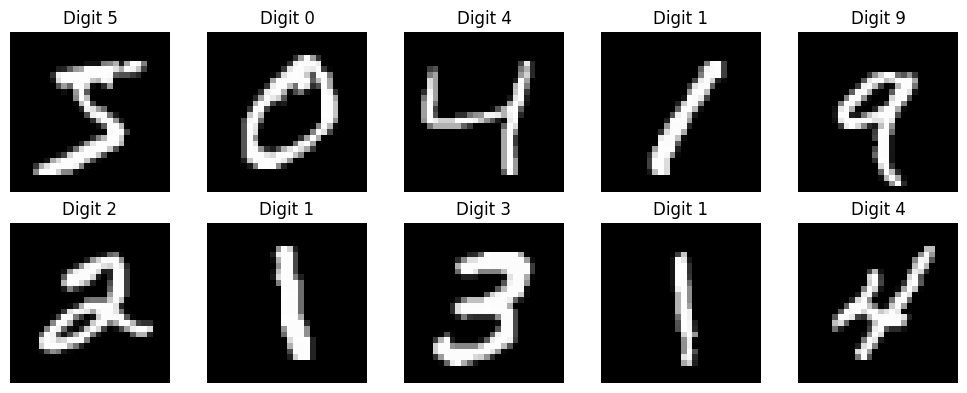

In [4]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title("Digit " + str(y_train[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Encoder
input_img = Input(shape=(784,))

encoded = Dense(128, activation='relu')(input_img)
encoded = Dense(64, activation='relu')(encoded)

latent = Dense(2, activation='linear', name='latent_space')(encoded)

encoder = Model(input_img, latent, name='encoder')

# Decoder
decoder_input = Input(shape=(2,))

decoded = Dense(64, activation='relu')(decoder_input)
decoded = Dense(128, activation='relu')(decoded)

output_img = Dense(784, activation='sigmoid')(decoded)

decoder = Model(decoder_input, output_img, name='decoder')

# Complete Autoencoder
autoencoder_output = decoder(encoder(input_img))

autoencoder = Model(input_img, autoencoder_output)

print("Basic Autoencoder created successfully!")
autoencoder.summary()

Basic Autoencoder created successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 2)              │       108,866 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       109,648 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,514 (853.57 KB)

 Trainable params: 218,514 (853.57 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

ae_history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    validation_data=(x_test, x_test),
    verbose=1
)

print("Basic Autoencoder training completed!")

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.2765 - val_loss: 0.2314
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2239 - val_loss: 0.2152
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2113 - val_loss: 0.2047
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2022 - val_loss: 0.1983
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1961 - val_loss: 0.1932
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1921 - val_loss: 0.1899
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1893 - val_loss: 0.1879
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1874 - val_loss: 0.1862
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1858 - val_loss: 0.1848
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1845 - val_loss: 0.1841
Basic Autoencoder training completed!


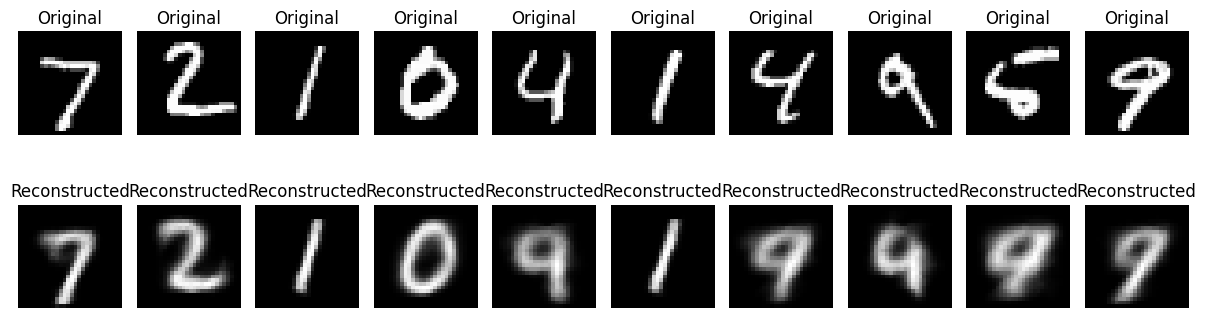

In [7]:
reconstructed = autoencoder.predict(x_test[:10], verbose=0)

plt.figure(figsize=(12, 4))

for i in range(10):

    # Original
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Original")

    # Reconstructed
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Reconstructed")

plt.tight_layout()
plt.show()

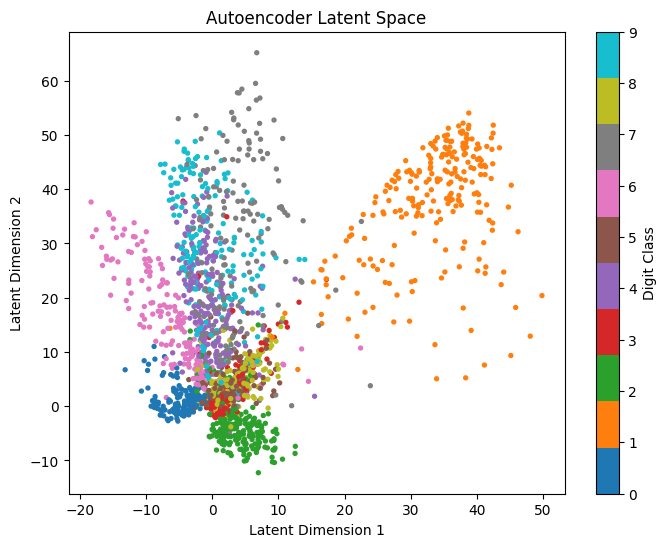

In [8]:
latent_features = encoder.predict(x_test[:2000], verbose=0)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    latent_features[:, 0],
    latent_features[:, 1],
    c=y_test[:2000],
    cmap='tab10',
    s=8
)

plt.colorbar(scatter, label='Digit Class')
plt.title("Autoencoder Latent Space")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.show()

In [9]:
noise_factor = 0.4

x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_test.shape
)

# Keep pixel values between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)

print("Gaussian noise added successfully!")

Gaussian noise added successfully!


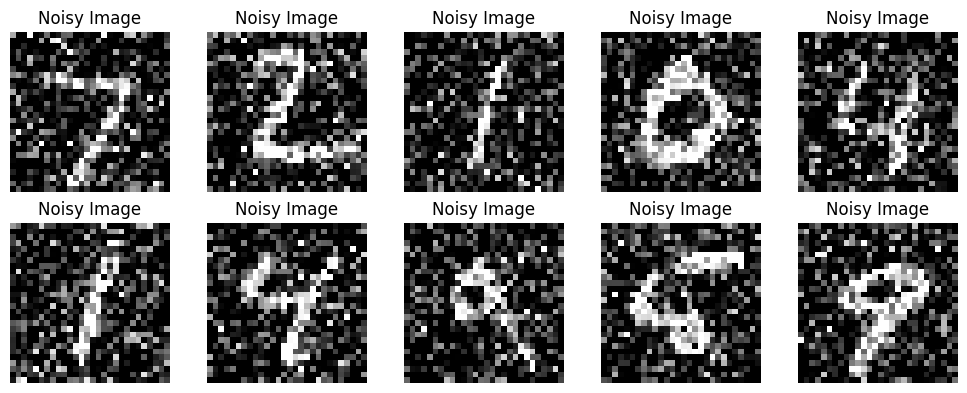

In [10]:
plt.figure(figsize=(10, 4))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        x_test_noisy[i].reshape(28, 28),
        cmap='gray'
    )

    plt.title("Noisy Image")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:
dae_input = Input(shape=(784,))

# Encoder
dae_encoded = Dense(128, activation='relu')(dae_input)
dae_encoded = Dense(64, activation='relu')(dae_encoded)
dae_encoded = Dense(32, activation='relu')(dae_encoded)

# Decoder
dae_decoded = Dense(64, activation='relu')(dae_encoded)
dae_decoded = Dense(128, activation='relu')(dae_decoded)

dae_output = Dense(784, activation='sigmoid')(dae_decoded)

dae = Model(dae_input, dae_output)

print("Denoising Autoencoder created successfully!")
dae.summary()

Denoising Autoencoder created successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
dae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

dae_history = dae.fit(
    x_train_noisy,
    x_train,
    epochs=10,
    batch_size=256,
    validation_data=(x_test_noisy, x_test),
    verbose=1
)

print("Denoising Autoencoder training completed!")

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.2615 - val_loss: 0.1945
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1733 - val_loss: 0.1579
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1531 - val_loss: 0.1456
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1435 - val_loss: 0.1389
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1375 - val_loss: 0.1343
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1331 - val_loss: 0.1297
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1299 - val_loss: 0.1272
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1274 - val_loss: 0.1264
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1257 - val_loss: 0.1236
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1238 - val_loss: 0.1220
Denoising Autoencoder training completed!


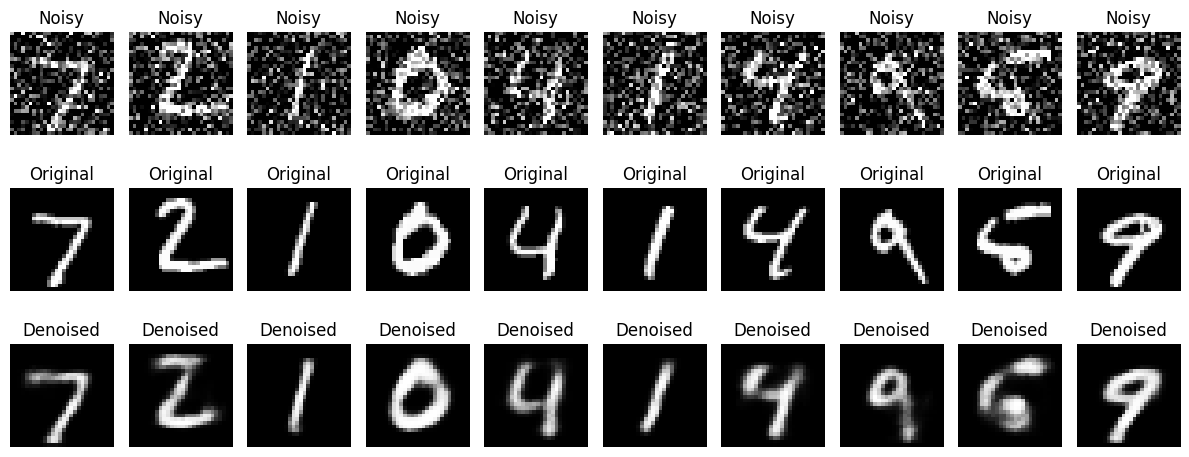

In [13]:
denoised = dae.predict(x_test_noisy[:10], verbose=0)

plt.figure(figsize=(12, 5))

for i in range(10):

    # Noisy image
    plt.subplot(3, 10, i + 1)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Noisy")

    # Clean image
    plt.subplot(3, 10, i + 11)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Original")

    # Denoised image
    plt.subplot(3, 10, i + 21)
    plt.imshow(denoised[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Denoised")

plt.tight_layout()
plt.show()

In [14]:
latent_dim = 2

vae_input = Input(shape=(784,))

x = Dense(128, activation='relu')(vae_input)
x = Dense(64, activation='relu')(x)

z_mean = Dense(latent_dim, name='z_mean')(x)
z_log_var = Dense(latent_dim, name='z_log_var')(x)

print("VAE encoder layers created successfully!")

VAE encoder layers created successfully!


In [15]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Define input
vae_input = layers.Input(shape=(784,))

# Encoder layers
x = layers.Dense(256, activation='relu')(vae_input)

z_mean = layers.Dense(2, name='z_mean')(x)
z_log_var = layers.Dense(2, name='z_log_var')(x)

# Sampling layer
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Apply sampling
z = Sampling()([z_mean, z_log_var])

# Create encoder
vae_encoder = Model(
    vae_input,
    [z_mean, z_log_var, z],
    name='vae_encoder'
)

print("Reparameterization trick implemented successfully!")

Reparameterization trick implemented successfully!


In [16]:
# Create decoder input
latent_inputs = layers.Input(shape=(2,))

# Decoder layers
decoder_hidden = layers.Dense(256, activation='relu')(latent_inputs)

decoder_output = layers.Dense(
    784,
    activation='sigmoid'
)(decoder_hidden)

# Create decoder model
vae_decoder = Model(
    latent_inputs,
    decoder_output,
    name='vae_decoder'
)

print("VAE Decoder created successfully!")

VAE Decoder created successfully!


In [17]:
# Connect encoder output to decoder
z_mean, z_log_var, z = vae_encoder(vae_input)

vae_output = vae_decoder(z)

# Create VAE model
vae = Model(
    vae_input,
    vae_output,
    name='VAE'
)

print("VAE model connected successfully!")

VAE model connected successfully!


In [18]:
# Connect encoder output to decoder
z_mean, z_log_var, z = vae_encoder(vae_input)

vae_output = vae_decoder(z)

# Create VAE model
vae = Model(
    vae_input,
    vae_output,
    name='VAE'
)

print("VAE model connected successfully!")

VAE model connected successfully!


In [20]:
class VAE(Model):

    def __init__(self, encoder, decoder):
        super(VAE, self).__init__()
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            z_mean, z_log_var, z = self.encoder(data)

            reconstruction = self.decoder(z)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(
                        data, reconstruction
                    ),
                    axis=-1
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss, self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }

vae = VAE(vae_encoder, vae_decoder)

vae.compile(optimizer='adam')

print("VAE loss function created successfully!")

VAE loss function created successfully!


In [21]:
history = vae.fit(
    x_train,
    epochs=10,
    batch_size=128
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - kl_loss: 1.8733 - loss: 24.9446 - reconstruction_loss: 23.0712
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - kl_loss: 2.0360 - loss: 24.4155 - reconstruction_loss: 22.3795
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 2.4735 - loss: 24.4531 - reconstruction_loss: 21.9796
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 2.3817 - loss: 23.9147 - reconstruction_loss: 21.5330
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 2.1531 - loss: 24.2050 - reconstruction_loss: 22.0519
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 2.4208 - loss: 22.4682 - reconstruction_loss: 20.0474
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 2.5812 - loss: 22.7414 - reconstruction_loss: 20.1602
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 2.8016 - loss: 22.0969 - reconstruction_loss: 19.2953
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 2

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 524ms/step


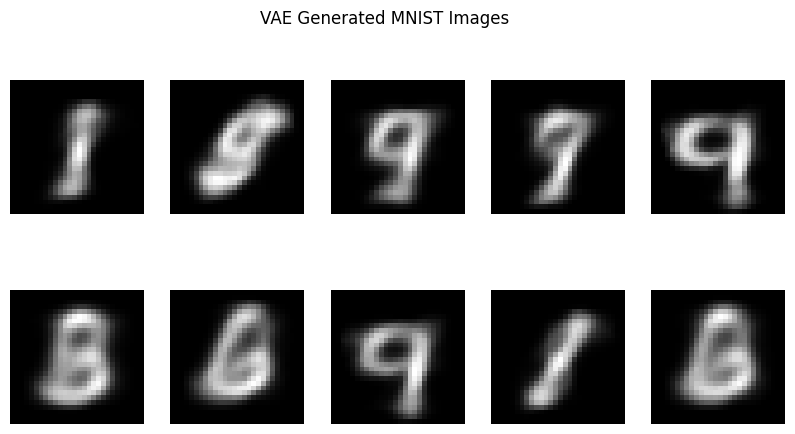

10 new images generated successfully!


In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Generate random latent points
random_latent_points = np.random.normal(
    size=(10, 2)
).astype("float32")

# Generate images using decoder
generated_images = vae_decoder.predict(
    random_latent_points
)

# Display generated images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        generated_images[i].reshape(28, 28),
        cmap='gray'
    )
    plt.axis('off')

plt.suptitle("VAE Generated MNIST Images")
plt.show()

print("10 new images generated successfully!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 543ms/step


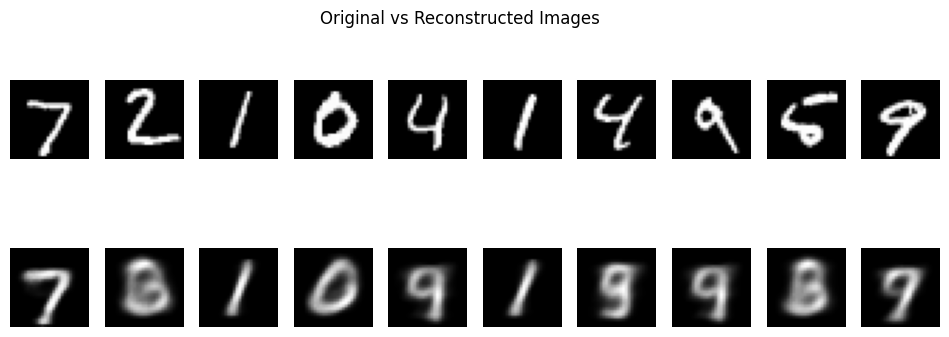

Image comparison completed!


In [23]:
# Reconstruct test images
reconstructed_images = vae.predict(x_test[:10])

plt.figure(figsize=(12, 4))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        reconstructed_images[i].reshape(28, 28),
        cmap='gray'
    )
    plt.axis('off')

plt.suptitle("Original vs Reconstructed Images")
plt.show()

print("Image comparison completed!")

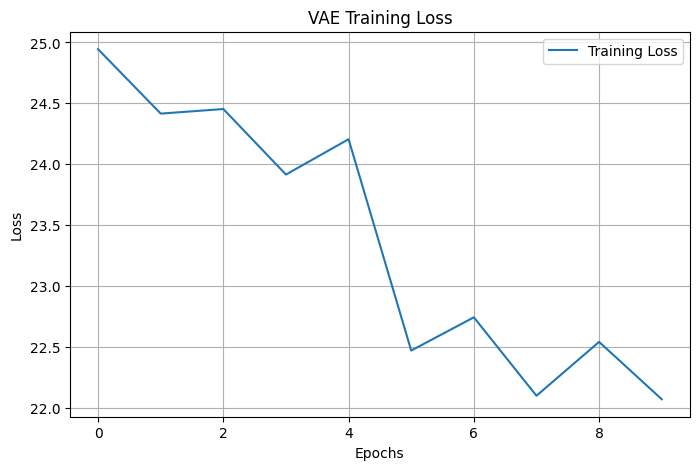

Training loss graph displayed!


In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid()

plt.show()

print("Training loss graph displayed!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


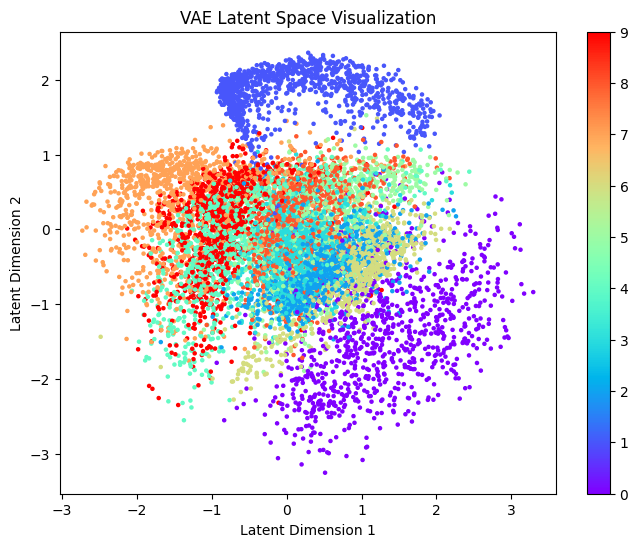

VAE latent space visualized successfully!


In [25]:
# Get latent representations
z_mean, z_log_var, z = vae_encoder.predict(x_test)

# Plot latent space
plt.figure(figsize=(8, 6))

plt.scatter(
    z_mean[:, 0],
    z_mean[:, 1],
    c=y_test,
    cmap='rainbow',
    s=5
)

plt.colorbar()
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("VAE Latent Space Visualization")
plt.show()

print("VAE latent space visualized successfully!")

In [26]:
print("Basic Autoencoder completed!")
print("Denoising Autoencoder completed!")
print("Variational Autoencoder completed!")
print("All models executed successfully!")

Basic Autoencoder completed!
Denoising Autoencoder completed!
Variational Autoencoder completed!
All models executed successfully!


In [27]:
basic_loss = autoencoder.evaluate(
    x_test, x_test, verbose=0
)

print("Basic Autoencoder Test Loss:", basic_loss)

Basic Autoencoder Test Loss: 0.18408748507499695


In [29]:
dae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

print("Denoising Autoencoder compiled successfully!")

Denoising Autoencoder compiled successfully!


In [32]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model

# Prepare MNIST test data
(_, _), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_test = x_test.astype("float32") / 255.0
x_test = x_test.reshape(-1, 784)

# Add Gaussian noise
noise_factor = 0.4

noisy_x_test = x_test + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_test.shape
)

noisy_x_test = np.clip(noisy_x_test, 0.0, 1.0)

print("Test data created successfully!")
print("Noisy test shape:", noisy_x_test.shape)
print("Original test shape:", x_test.shape)

Test data created successfully!
Noisy test shape: (10000, 784)
Original test shape: (10000, 784)


In [33]:
dae_input = layers.Input(shape=(784,))

x = layers.Dense(256, activation='relu')(dae_input)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dense(256, activation='relu')(x)

dae_output = layers.Dense(784, activation='sigmoid')(x)

dae = Model(dae_input, dae_output)

dae.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

print("Denoising Autoencoder created successfully!")

Denoising Autoencoder created successfully!


In [34]:
dae.fit(
    noisy_x_test,
    x_test,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.3107 - val_loss: 0.2546
Epoch 2/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2145 - val_loss: 0.1933
Epoch 3/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1737 - val_loss: 0.1690
Epoch 4/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1533 - val_loss: 0.1528
Epoch 5/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1416 - val_loss: 0.1450


In [35]:
dae_loss = dae.evaluate(
    noisy_x_test,
    x_test,
    verbose=0
)

print("Denoising Autoencoder Test Loss:", dae_loss)

Denoising Autoencoder Test Loss: 0.13732002675533295


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step


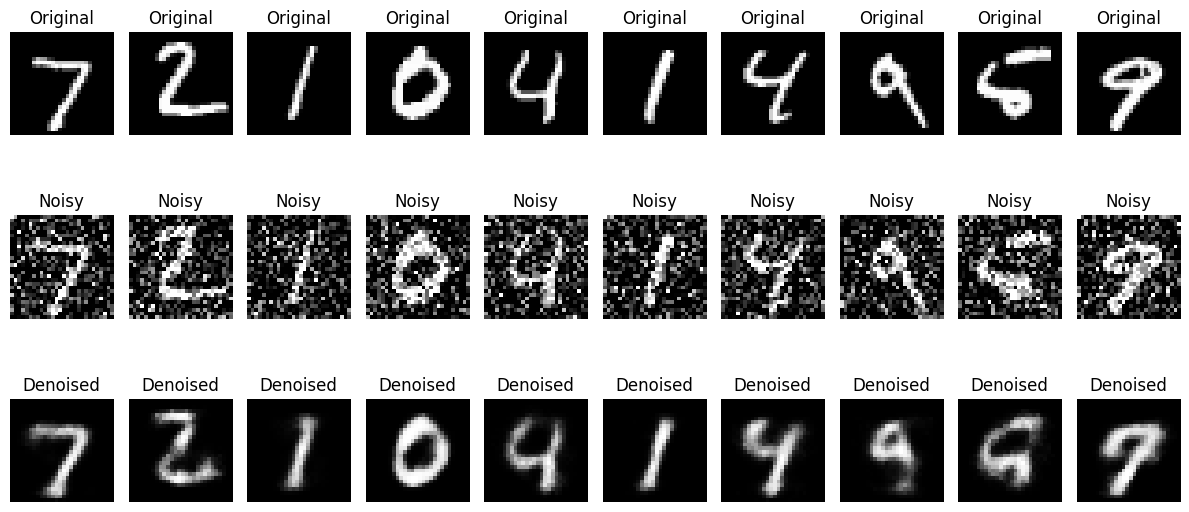

Denoising visualization completed!


In [36]:
import matplotlib.pyplot as plt

denoised_images = dae.predict(noisy_x_test[:10])

plt.figure(figsize=(12, 6))

for i in range(10):

    # Original images
    plt.subplot(3, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Noisy images
    plt.subplot(3, 10, i + 11)
    plt.imshow(noisy_x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Noisy")
    plt.axis('off')

    # Denoised images
    plt.subplot(3, 10, i + 21)
    plt.imshow(denoised_images[i].reshape(28, 28), cmap='gray')
    plt.title("Denoised")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Denoising visualization completed!")

In [37]:
dae.save("denoising_autoencoder.keras")

print("Denoising Autoencoder saved successfully!")

Denoising Autoencoder saved successfully!


In [38]:
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("----------------------------------")
print("1. Basic Autoencoder implemented")
print("2. Denoising Autoencoder implemented")
print("3. Variational Autoencoder implemented")
print("4. Image reconstruction completed")
print("5. Latent space visualization completed")
print("6. New MNIST images generated")

EXPERIMENT COMPLETED SUCCESSFULLY
----------------------------------
1. Basic Autoencoder implemented
2. Denoising Autoencoder implemented
3. Variational Autoencoder implemented
4. Image reconstruction completed
5. Latent space visualization completed
6. New MNIST images generated


In [40]:
history_basic = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, x_test)
)

print("Basic Autoencoder training completed!")

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.1842 - val_loss: 0.1836
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1826 - val_loss: 0.1820
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1814 - val_loss: 0.1813
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1803 - val_loss: 0.1808
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1795 - val_loss: 0.1794
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1788 - val_loss: 0.1789
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1782 - val_loss: 0.1783
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1776 - val_loss: 0.1777
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1769 - val_loss: 0.1773
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1762 - val_loss: 0.1770
Basic Autoencoder training completed!


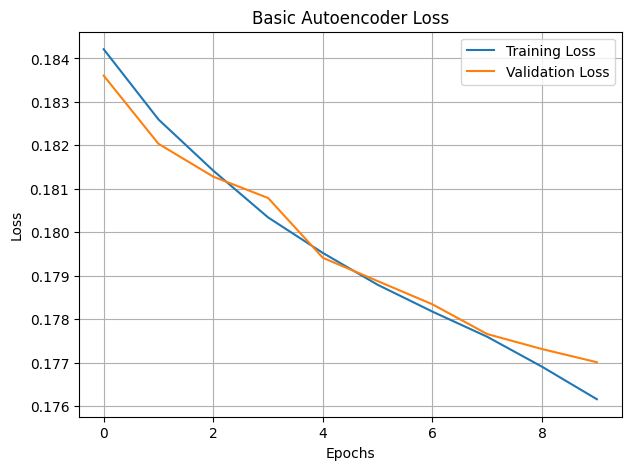

Basic Autoencoder graph displayed!


In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(history_basic.history['loss'], label='Training Loss')
plt.plot(history_basic.history['val_loss'], label='Validation Loss')

plt.title("Basic Autoencoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

print("Basic Autoencoder graph displayed!")